In [3]:
import os
import glob
import pandas as pd

# ------------------------------------------------------------------
# CONFIG
# ------------------------------------------------------------------

# Separate folders for results
MI_RESULTS_DIR = "results_sign_genes/"
ORIGINAL_RESULTS_DIR = "results_original_GEMLI/"

# Where to write the averaged dfs used by the plotting script
OUTPUT_BASE = "dfs_for_plotting_csv"

# Datasets we want to process
DATASETS = [
    "treutlein",
    "weinreb",
    "junker",
    "you1",
    "you2",
    "you3",
    "you4",
    "knoblich_day16_1",
    "knoblich_day16_2",
    "knoblich_day42_1",
    "knoblich_day42_2",
]

# Filename patterns (dataset-dependent part only)
ORIGINAL_PATTERN_TEMPLATE = "*original_GEMLI*{dataset}*5000*"
MI_PATTERN_TEMPLATE       = "*GEMLI*1300*{dataset}*5000*"


# ------------------------------------------------------------------
# Helper to average multiple csv runs
# ------------------------------------------------------------------

def mean_over_runs(file_list):
    """Read multiple CSVs, stack by rows, and average per index."""
    if not file_list:
        return None

    dfs = [pd.read_csv(f) for f in file_list]
    stacked_df = pd.concat(dfs, axis=0)
    mean_df = stacked_df.groupby(stacked_df.index).mean()
    mean_df.reset_index(drop=True, inplace=True)
    return mean_df


# ------------------------------------------------------------------
# Main loop over datasets
# ------------------------------------------------------------------

os.makedirs(OUTPUT_BASE, exist_ok=True)

for dataset in DATASETS:

    original_pattern = os.path.join(
        ORIGINAL_RESULTS_DIR,
        ORIGINAL_PATTERN_TEMPLATE.format(dataset=dataset),
    )
    mi_pattern = os.path.join(
        MI_RESULTS_DIR,
        MI_PATTERN_TEMPLATE.format(dataset=dataset),
    )

    original_files = glob.glob(original_pattern)
    mi_files = glob.glob(mi_pattern)

    print(f"\n=== {dataset} ===")
    print(f"  Found {len(original_files)} original GEMLI files")
    print(f"  Found {len(mi_files)} MI (1300 genes) files")

    if not original_files or not mi_files:
        print("  -> Skipping: missing files for this dataset.")
        continue

    mean_original = mean_over_runs(original_files)
    mean_mi = mean_over_runs(mi_files)

    if mean_original is None or mean_mi is None:
        print("  -> Skipping: could not build mean DataFrames.")
        continue

    # Output structure unchanged
    out_dir = os.path.join(OUTPUT_BASE, dataset)
    os.makedirs(out_dir, exist_ok=True)

    mean_original.to_csv(os.path.join(out_dir, "df_0.csv"), index=False)
    mean_mi.to_csv(os.path.join(out_dir, "df_1.csv"), index=False)

    print(f"  -> Saved {out_dir}/df_0.csv")
    print(f"  -> Saved {out_dir}/df_1.csv")

print("\nDone. You can now run your multi-panel plotting script.")



=== treutlein ===
  Found 5 original GEMLI files
  Found 5 MI (1300 genes) files
  -> Saved dfs_for_plotting_csv/treutlein/df_0.csv
  -> Saved dfs_for_plotting_csv/treutlein/df_1.csv

=== weinreb ===
  Found 5 original GEMLI files
  Found 5 MI (1300 genes) files
  -> Saved dfs_for_plotting_csv/weinreb/df_0.csv
  -> Saved dfs_for_plotting_csv/weinreb/df_1.csv

=== junker ===
  Found 5 original GEMLI files
  Found 5 MI (1300 genes) files
  -> Saved dfs_for_plotting_csv/junker/df_0.csv
  -> Saved dfs_for_plotting_csv/junker/df_1.csv

=== you1 ===
  Found 5 original GEMLI files
  Found 5 MI (1300 genes) files
  -> Saved dfs_for_plotting_csv/you1/df_0.csv
  -> Saved dfs_for_plotting_csv/you1/df_1.csv

=== you2 ===
  Found 5 original GEMLI files
  Found 5 MI (1300 genes) files
  -> Saved dfs_for_plotting_csv/you2/df_0.csv
  -> Saved dfs_for_plotting_csv/you2/df_1.csv

=== you3 ===
  Found 5 original GEMLI files
  Found 5 MI (1300 genes) files
  -> Saved dfs_for_plotting_csv/you3/df_0.csv
  

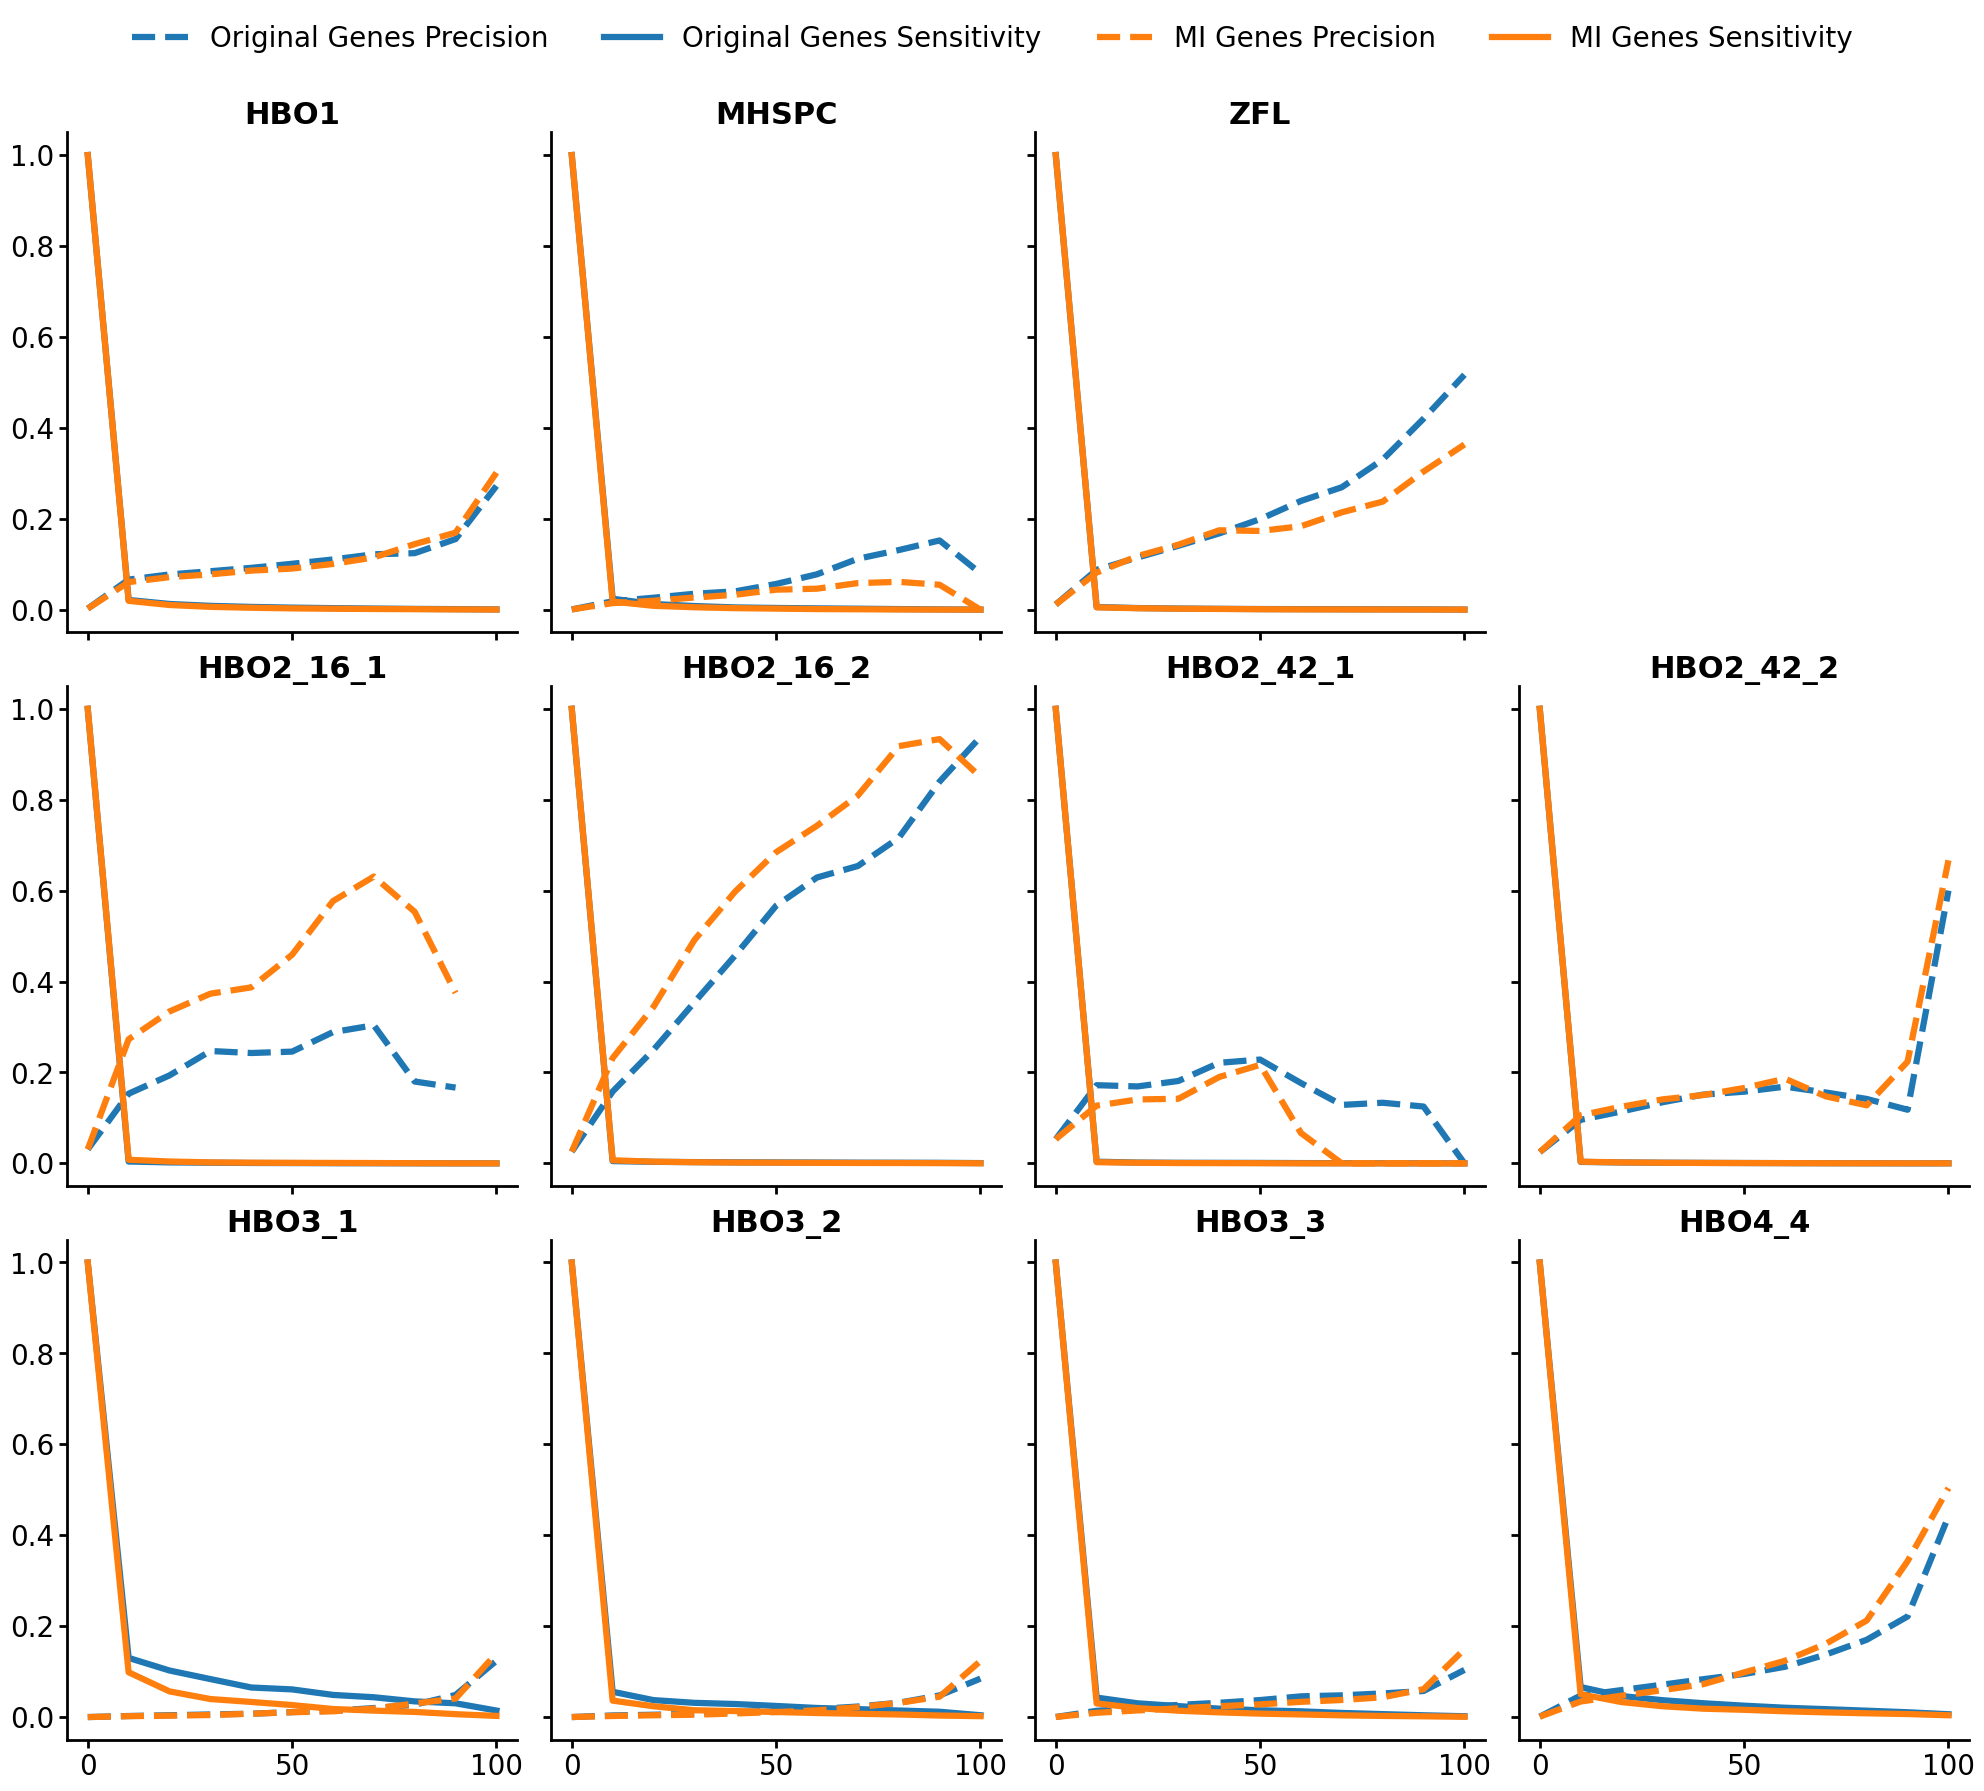

In [4]:
import os
import pandas as pd
import matplotlib.pyplot as plt

# Path to the folder containing CSV files
base_path = 'dfs_for_plotting_csv/'

# Confidence levels for x-axis
confidence_levels = list(range(11))  # [0, 1, 2, ..., 10]

# Dataset name mappings (folder name -> abbreviation)
dataset_abbreviations = {
    "treutlein": "HBO1",
    "weinreb": "MHSPC",
    "junker": "ZFL",
    "you1": "HBO3_1",
    "you2": "HBO3_2",
    "you3": "HBO3_3",
    "you4": "HBO4_4",
    "knoblich_day16_1": "HBO2_16_1",
    "knoblich_day16_2": "HBO2_16_2",
    "knoblich_day42_1": "HBO2_42_1",
    "knoblich_day42_2": "HBO2_42_2",
}

# Desired order of rows and datasets in each row
row_order = [
    ["HBO1", "MHSPC", "ZFL", None],
    ["HBO2_16_1", "HBO2_16_2", "HBO2_42_1", "HBO2_42_2"],
    ["HBO3_1", "HBO3_2", "HBO3_3", "HBO4_4"],
]

# Load and map dataset names to data
all_data = []
excluded_folder = 'morris'

for folder in os.listdir(base_path):
    folder_path = os.path.join(base_path, folder)
    if os.path.isdir(folder_path) and folder != excluded_folder:  # Exclude 'morris'
        try:
            df_0 = pd.read_csv(os.path.join(folder_path, 'df_0.csv'))
            df_1 = pd.read_csv(os.path.join(folder_path, 'df_1.csv'))
            dataset_name = dataset_abbreviations.get(folder, folder)
            all_data.append((dataset_name, df_0, df_1))
        except Exception as e:
            print(f"Error processing folder {folder}: {e}")

# Sort datasets based on row order
sorted_data = []
for row in row_order:
    for dataset_name in row:
        for data in all_data:
            if data[0] == dataset_name:
                sorted_data.append(data)
        if dataset_name is None:  # Append a placeholder for empty slots
            sorted_data.append(None)

# Define the number of rows and columns for subplots
n_rows = len(row_order)
n_cols = max(len(row) for row in row_order)

# Create a subplot figure
fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, n_rows * 6), sharex=True, sharey=True)
axes = axes.flatten()  # Flatten axes for easier iteration

# Define consistent color scheme
colors = plt.cm.tab10([0, 1])  # Two colors for precision and sensitivity

# Plot datasets
for i, item in enumerate(sorted_data):
    ax = axes[i]
    if item is None:  # Empty subplot
        ax.axis('off')  # Turn off the axis for empty slots
        continue

    dataset_name, df_0, df_1 = item

    # Plot precision and sensitivity for original genes (df_0)
    ax.plot(confidence_levels, df_0['precision'], label='Original Genes Precision', color=colors[0], linestyle='--', linewidth=4.5)
    ax.plot(confidence_levels, df_0['sensitivity'], label='Original Genes Sensitivity', color=colors[0], linewidth=4.5)

    # Plot precision and sensitivity for MI genes (df_1)
    ax.plot(confidence_levels, df_1['precision'], label='MI Genes Precision', color=colors[1], linestyle='--', linewidth=4.5)
    ax.plot(confidence_levels, df_1['sensitivity'], label='MI Genes Sensitivity', color=colors[1], linewidth=4.5)

    # Set title for each subplot
    ax.set_title(dataset_name, fontsize=22, fontweight='bold')

    # Customize subplot appearance
    ax.spines['top'].set_linewidth(0)
    ax.spines['right'].set_linewidth(0)
    ax.spines['left'].set_linewidth(2)
    ax.spines['bottom'].set_linewidth(2)
    ax.set_xticks([0, 5, 10])
    ax.set_xticklabels(["0", "50", "100"], fontsize=20)
    ax.tick_params(axis='both', which='major', labelsize=20, width=2, length=6)

# Remove unused subplots
for j in range(len(sorted_data), len(axes)):
    fig.delaxes(axes[j])

# Add a single legend at the top
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', fontsize=20, ncol=4, frameon=False)

# Adjust layout
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.savefig("precision_sensitivity_corrected_layout.pdf", dpi=300)
plt.show()


## make GEMLI vs MI genes plot 

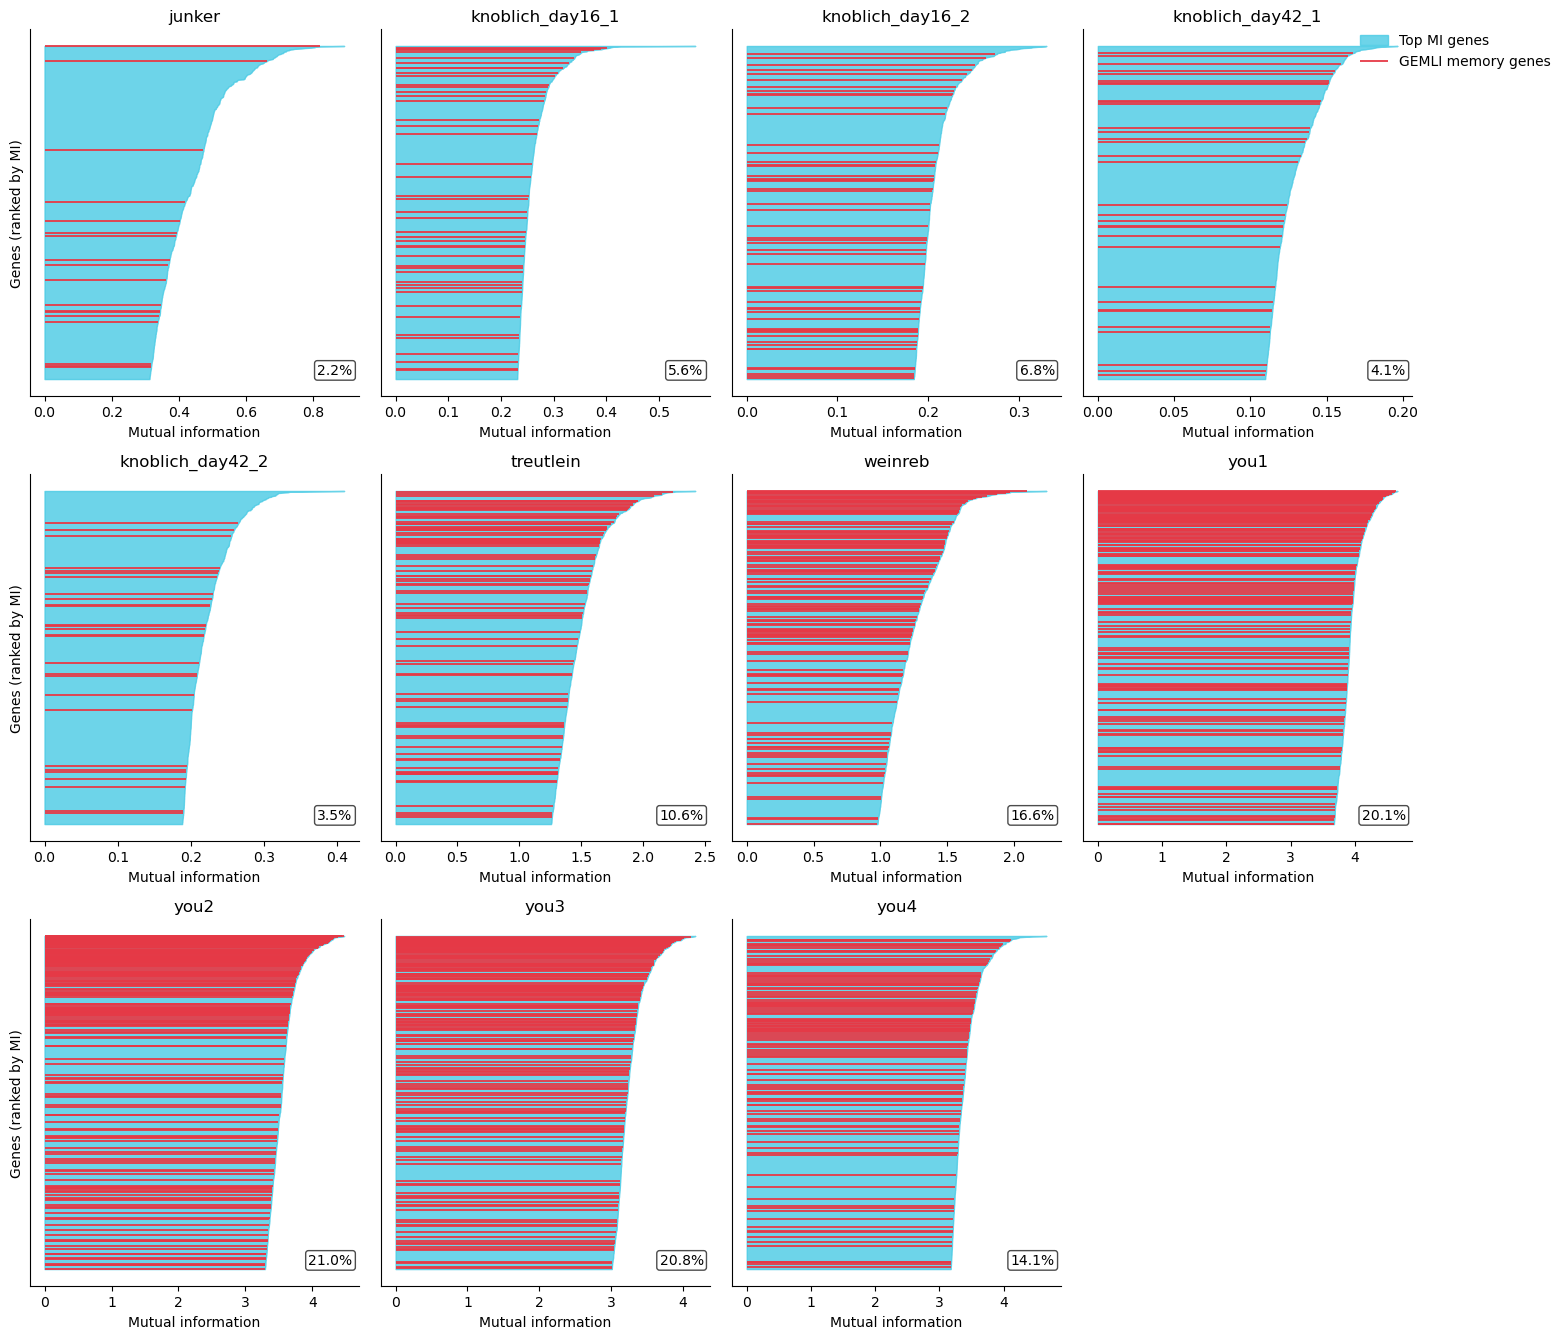

Percentage of GEMLI memory genes among top 800 MI genes per dataset:
  junker            :  2.25%
  knoblich_day16_1  :  5.62%
  knoblich_day16_2  :  6.75%
  knoblich_day42_1  :  4.12%
  knoblich_day42_2  :  3.50%
  treutlein         : 10.62%
  weinreb           : 16.62%
  you1              : 20.12%
  you2              : 21.00%
  you3              : 20.75%
  you4              : 14.12%


In [25]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# -----------------------------
# CONFIG
# -----------------------------
# Datasets in the same naming scheme as MI and GEMLI outputs
DATASETS = [
  "junker",
  "knoblich_day16_1",
  "knoblich_day16_2",
  "knoblich_day42_1",
  "knoblich_day42_2",
  "treutlein",
  "weinreb",
  "you1",
      "you2",
      "you3",
    "you4",
]

# Base paths – adapt these to your system
BASE_MI = (
    "MIscores/"
)

BASE_GEMLI = (
    ""
)

# Column name for the 95% permuted MI threshold
MI_THRESHOLD_COL = "95_perm_mi"  # your MI files have this name, not "95_perm_mi"

TOP_N = 800  # number of top MI genes to consider

# -----------------------------
# Helper to load MI dataframe
# -----------------------------
def load_mi_df(dataset):
    mi_path = os.path.join(
        BASE_MI, f"MI_label_entropy_{dataset}_50_permutations.csv"
    )
    df = pd.read_csv(mi_path)
    return df

# -----------------------------
# Helper to load GEMLI memory genes
# -----------------------------
def load_gemli_genes(dataset):
    """
    Tries two filename patterns:
    1) GEMLI_memory_genes_<dataset>.csv   (from the R export script)
    2) <dataset>_GEMLI_memory_genes.csv   (your example path)
    Adjust if you only use one convention.
    """
    candidates = [
        os.path.join(BASE_GEMLI, f"GEMLI_memory_genes_significant_{dataset}.csv"),
        os.path.join(BASE_GEMLI, f"{dataset}_GEMLI_memory_genes.csv"),
    ]
    for path in candidates:
        if os.path.exists(path):
            df = pd.read_csv(path, header=None)
            # For safety: take all columns as strings (first column is enough)
            genes = df.iloc[:, 0].astype(str).tolist()
            return genes, path
    raise FileNotFoundError(
        f"No GEMLI memory gene file found for {dataset}.\n"
        f"Tried: {candidates}"
    )

# -----------------------------
# Prepare figure grid
# -----------------------------
n_datasets = len(DATASETS)

# Simple grid: 3 rows x 4 cols for 11 datasets -> one empty panel
n_cols = 4
n_rows = int(np.ceil(n_datasets / n_cols))

fig, axes = plt.subplots(
    n_rows, n_cols, figsize=(4 * n_cols, 4.5 * n_rows), sharex=False, sharey=False
)
axes = axes.flatten()

percentages = {}  # store percentage of GEMLI genes in top N for each dataset

# -----------------------------
# Loop over datasets
# -----------------------------
for idx, dataset in enumerate(DATASETS):
    ax = axes[idx]

    # ---- Load MI df ----
    mi_df = load_mi_df(dataset)

    # Filter MI > threshold
    mi_sig = mi_df.loc[mi_df["true_mi"] > 0].copy()

    # Sort by true_mi descending
    mi_sorted = mi_sig.sort_values(by="true_mi", ascending=False)

    # Select top N
    n_top = min(TOP_N, mi_sorted.shape[0])
    top_values = mi_sorted["true_mi"].head(n_top).values
    top_genes = mi_sorted["gene"].head(n_top).values

    # ---- Load GEMLI memory genes ----
    gemli_genes, gemli_path = load_gemli_genes(dataset)

    # Indices of top genes that are GEMLI memory genes
    red_indices = [i for i, gene in enumerate(top_genes) if gene in gemli_genes]

    # ---- Plot ----
    # Vertical teal-ish filled area
    ax.fill_betweenx(
        range(len(top_values)),
        0,
        top_values,
        color="#48cae4",
        alpha=0.8,
        label="Top MI genes",
    )

    # Red horizontal stripes where GEMLI genes appear
    if red_indices:
        ax.hlines(
            red_indices,
            xmin=0,
            xmax=np.array(top_values)[red_indices],
            color="#e63946",
            linewidth=1.3,
            label="GEMLI memory genes",
        )

    # Flip y-axis so highest MI at top
    ax.invert_yaxis()

    # Clean up
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.yaxis.set_ticks([])
    ax.grid(False)

    # Titles and labels
    ax.set_title(dataset, fontsize=12)
    if idx % n_cols == 0:
        ax.set_ylabel("Genes (ranked by MI)")
    ax.set_xlabel("Mutual information")

    # Percentage of GEMLI genes in top N
    percentage = len(red_indices) / n_top * 100 if n_top > 0 else 0.0
    percentages[dataset] = percentage

    # Show percentage as small text in the corner
    ax.text(
        0.98,
        0.05,
        f"{percentage:.1f}%",
        transform=ax.transAxes,
        ha="right",
        va="bottom",
        fontsize=10,
        bbox=dict(boxstyle="round,pad=0.2", facecolor="white", alpha=0.7),
    )

# Hide any unused subplots if grid bigger than #datasets
for j in range(n_datasets, len(axes)):
    fig.delaxes(axes[j])

# Handle legend: create a single legend for the whole figure
# Use first axis with data
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    loc="upper right",
    bbox_to_anchor=(0.98, 0.98),
    frameon=False,
)

plt.tight_layout(rect=[0, 0, 0.9, 1])  # leave space on the right for legend
plt.savefig("GEMLI_genes_with_MI.pdf")
plt.show()

# -----------------------------
# Print percentages to console
# -----------------------------
print("Percentage of GEMLI memory genes among top "
      f"{TOP_N} MI genes per dataset:")
for ds, perc in percentages.items():
    print(f"  {ds:18s}: {perc:5.2f}%")


# GEMLI on ATAC (morris) data 

In [18]:
import os
import glob
import pandas as pd

# ------------------------------------------------------------------
# CONFIG
# ------------------------------------------------------------------

# Separate folders for results
MI_RESULTS_DIR = "results_sign_genes/"
ORIGINAL_RESULTS_DIR = "results_original_GEMLI/"

# Where to write the averaged dfs used by the plotting script
OUTPUT_BASE = "dfs_for_plotting_csv"

# Datasets we want to process (added morris_rna + morris_atac)
DATASETS = [
    "morris_rna",
    "morris_atac",
]

# Filename patterns (dataset-dependent part only)
ORIGINAL_PATTERN_TEMPLATE = "*original_GEMLI*{dataset}*5000*"
MI_PATTERN_TEMPLATE       = "*GEMLI*1300*{dataset}*5000*"

# ------------------------------------------------------------------
# Helper to average multiple csv runs
# ------------------------------------------------------------------

def mean_over_runs(file_list):
    """Read multiple CSVs, stack by rows, and average per row position."""
    if not file_list:
        return None

    dfs = []
    for f in file_list:
        df = pd.read_csv(f)
        # ensure row-position alignment across runs
        df = df.reset_index(drop=True)
        dfs.append(df)

    stacked_df = pd.concat(dfs, axis=0, ignore_index=True)

    # average per original row-position (0..n_rows-1)
    # after concat, we reconstruct a row-position id
    n_rows = dfs[0].shape[0]
    row_id = stacked_df.index % n_rows
    mean_df = stacked_df.groupby(row_id).mean(numeric_only=True).reset_index(drop=True)

    return mean_df

# ------------------------------------------------------------------
# Main loop over datasets
# ------------------------------------------------------------------

os.makedirs(OUTPUT_BASE, exist_ok=True)

for dataset in DATASETS:

    original_pattern = os.path.join(
        ORIGINAL_RESULTS_DIR,
        ORIGINAL_PATTERN_TEMPLATE.format(dataset=dataset),
    )
    mi_pattern = os.path.join(
        MI_RESULTS_DIR,
        MI_PATTERN_TEMPLATE.format(dataset=dataset),
    )

    original_files = glob.glob(original_pattern)
    mi_files = glob.glob(mi_pattern)

    print(f"\n=== {dataset} ===")
    print(f"  Found {len(original_files)} original GEMLI files")
    print(f"  Found {len(mi_files)} MI (1300 genes) files")

    if not original_files or not mi_files:
        print("  -> Skipping: missing files for this dataset.")
        continue

    mean_original = mean_over_runs(original_files)
    mean_mi = mean_over_runs(mi_files)

    if mean_original is None or mean_mi is None:
        print("  -> Skipping: could not build mean DataFrames.")
        continue

    # Output structure unchanged
    out_dir = os.path.join(OUTPUT_BASE, dataset)
    os.makedirs(out_dir, exist_ok=True)

    mean_original.to_csv(os.path.join(out_dir, "df_0.csv"), index=False)
    mean_mi.to_csv(os.path.join(out_dir, "df_1.csv"), index=False)

    print(f"  -> Saved {out_dir}/df_0.csv")
    print(f"  -> Saved {out_dir}/df_1.csv")

print("\nDone. You can now run your multi-panel plotting script.")



=== morris_rna ===
  Found 5 original GEMLI files
  Found 5 MI (1300 genes) files
  -> Saved dfs_for_plotting_csv/morris_rna/df_0.csv
  -> Saved dfs_for_plotting_csv/morris_rna/df_1.csv

=== morris_atac ===
  Found 5 original GEMLI files
  Found 5 MI (1300 genes) files
  -> Saved dfs_for_plotting_csv/morris_atac/df_0.csv
  -> Saved dfs_for_plotting_csv/morris_atac/df_1.csv

Done. You can now run your multi-panel plotting script.


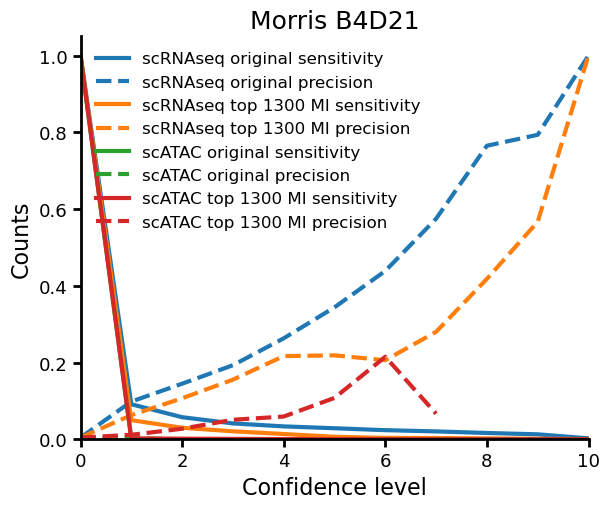

Saved: morris_B4D21_precision_sensitivity_overlay.pdf


In [24]:
import os
import pandas as pd
import matplotlib.pyplot as plt

# -------------------------------------------------------
# CONFIG
# -------------------------------------------------------
base_path = "dfs_for_plotting_csv/"
confidence_levels = list(range(11))  # 0..10

# Folder -> label prefix (like your example)
LABELS = {
    "morris_rna":  "scRNAseq",
    "morris_atac": "scATAC",
}

# Colors exactly like the example style:
# RNA: blue (original), orange (top)
# ATAC: green (original), red (top)
COLORS = {
    ("morris_rna",  "original"): "#1f77b4",  # blue
    ("morris_rna",  "top"):      "#ff7f0e",  # orange
    ("morris_atac", "original"): "#2ca02c",  # green
    ("morris_atac", "top"):      "#d62728",  # red
}

# Title + output
TITLE = "Morris B4D21"
OUTFILE = "morris_B4D21_precision_sensitivity_overlay.pdf"

# What your "top" set is called in the legend
RNA_TOP_TEXT  = "top 1300 MI"
ATAC_TOP_TEXT = "top 1300 MI"   # change if yours is also 1300

# -------------------------------------------------------
# LOAD
# -------------------------------------------------------
def load_pair(folder):
    folder_path = os.path.join(base_path, folder)
    df0 = pd.read_csv(os.path.join(folder_path, "df_0.csv"))  # original
    df1 = pd.read_csv(os.path.join(folder_path, "df_1.csv"))  # top/MI
    return df0, df1

df0_rna,  df1_rna  = load_pair("morris_rna")
df0_atac, df1_atac = load_pair("morris_atac")

# -------------------------------------------------------
# PLOT
# -------------------------------------------------------
fig, ax = plt.subplots(figsize=(6.2, 5.2))

# scRNAseq original
ax.plot(confidence_levels, df0_rna["sensitivity"],
        color=COLORS[("morris_rna", "original")], linewidth=3,
        label="scRNAseq original sensitivity")
ax.plot(confidence_levels, df0_rna["precision"],
        color=COLORS[("morris_rna", "original")], linewidth=3, linestyle="--",
        label="scRNAseq original precision")

# scRNAseq top
ax.plot(confidence_levels, df1_rna["sensitivity"],
        color=COLORS[("morris_rna", "top")], linewidth=3,
        label=f"scRNAseq {RNA_TOP_TEXT} sensitivity")
ax.plot(confidence_levels, df1_rna["precision"],
        color=COLORS[("morris_rna", "top")], linewidth=3, linestyle="--",
        label=f"scRNAseq {RNA_TOP_TEXT} precision")

# scATAC original
ax.plot(confidence_levels, df0_atac["sensitivity"],
        color=COLORS[("morris_atac", "original")], linewidth=3,
        label="scATAC original sensitivity")
ax.plot(confidence_levels, df0_atac["precision"],
        color=COLORS[("morris_atac", "original")], linewidth=3, linestyle="--",
        label="scATAC original precision")

# scATAC top
ax.plot(confidence_levels, df1_atac["sensitivity"],
        color=COLORS[("morris_atac", "top")], linewidth=3,
        label=f"scATAC {ATAC_TOP_TEXT} sensitivity")
ax.plot(confidence_levels, df1_atac["precision"],
        color=COLORS[("morris_atac", "top")], linewidth=3, linestyle="--",
        label=f"scATAC {ATAC_TOP_TEXT} precision")

# -------------------------------------------------------
# Styling like your example
# -------------------------------------------------------
ax.set_title(TITLE, fontsize=18)
ax.set_xlabel("Confidence level", fontsize=16)
ax.set_ylabel("Counts", fontsize=16)   # change to "Score" if you prefer

ax.set_xlim(0, 10)
ax.set_ylim(0, 1.05)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_linewidth(2)
ax.spines["bottom"].set_linewidth(2)

ax.tick_params(axis="both", which="major", labelsize=13, width=2, length=6)

ax.legend(loc="upper left", fontsize=12, frameon=False)

plt.tight_layout()
plt.savefig(OUTFILE, dpi=300)
plt.show()

print(f"Saved: {OUTFILE}")
